# 🏠 Predictive Insight Engine — House Price Prediction
**Supervised Learning Project (Regression, Gradient Descent, Bias–Variance)**

Role: Junior Data Scientist at a real-estate analytics firm.
Goal: Build and compare models that predict **house price** and explain **why some models perform better**.

Is notebook me **Task 1 se Task 30** tak sab task-wise diya hai (Part A to Part I).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
print("Libraries imported")

Libraries imported


---
# 🧠 Part A: Conceptual Understanding (Theory)

### Task 1: What are Supervised Learning Algorithms?
Supervised learning me model ko **labelled data** se sikhaya jata hai, matlab har input (features) ke saath uska sahi output (target) diya hota hai. Model input aur output ka relation seekhta hai, phir naye data ka output predict karta hai. Examples: Linear Regression, Logistic Regression, Decision Tree, KNN.

### Task 2: Regression vs Classification
- **Regression:** output **continuous number** hota hai (house price, salary, temperature). Metrics: MSE, RMSE, R².
- **Classification:** output **category/class** hota hai (spam / not spam, pass / fail). Metrics: accuracy, precision, recall.

### Task 3: Simple Linear Regression
Isme **ek independent variable (x)** se **ek dependent variable (y)** predict karte hain, straight line se: **y = b0 + b1·x**.
`b1` (slope) = x ek unit badhne par y kitna badhta hai, `b0` (intercept) = jab x = 0 ho tab y ki value. Line OLS method se milti hai (squared errors ka sum minimum).

### Task 4: Assumptions of Linear Regression
1. **Linearity:** x aur y ke beech relation straight-line type ho.
2. **Independence:** errors (residuals) ek dusre par depend na karein.
3. **Homoscedasticity:** errors ka spread har predicted value par almost same ho.
4. **Normality of residuals:** residuals roughly normal distribution follow karein.
5. **No multicollinearity:** independent features aapas me bahut zyada correlated na ho (multiple regression me).

### Task 5: Bias–Variance Trade-Off
- **Bias:** model bahut simple hai, isliye real pattern miss karta hai (underfitting).
- **Variance:** model bahut complex hai, training data ke noise ko bhi seekh leta hai (overfitting).
Simple model = high bias, low variance. Complex model = low bias, high variance. Humein beech ka best model chahiye jisme total test error kam ho.

### Task 6: Overfitting and Underfitting
- **Underfitting:** model train aur test dono pe kharab (e.g. curve wale data pe sirf straight line lagana).
- **Overfitting:** model train pe bahut accha but test pe kharab (e.g. degree 15 polynomial jo har training point ko touch kare, naye data pe galat predict kare).

---
# 🧪 Part B: Dataset Understanding & Preparation

Dataset file `house_prices.csv` isi folder me hai. (Agar official dataset use karna ho to usse isi naam se save karo. Columns ke naam same hone chahiye: House_Area, Bedrooms, Bathrooms, Location_Score, Age_of_Property, House_Price.)

In [2]:
df = pd.read_csv("house_prices.csv")

print("Shape:", df.shape)
print()
print("Missing values:")
print(df.isnull().sum())
df.head()

Shape: (1000, 6)

Missing values:
House_Area         0
Bedrooms           0
Bathrooms          0
Location_Score     0
Age_of_Property    0
House_Price        0
dtype: int64


,House_Area,Bedrooms,Bathrooms,Location_Score,Age_of_Property,House_Price
0,3209.0,3,2,7.4,3,169.88
1,2036.0,3,2,6.6,20,115.73
2,3505.0,4,3,1.0,33,169.31
3,2941.0,3,2,2.7,15,154.83
4,830.0,1,1,6.7,41,57.79


In [3]:
df.describe()

,House_Area,Bedrooms,Bathrooms,Location_Score,Age_of_Property,House_Price
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2240.124000,2.53400,1.921000,5.438500,25.349000,119.433890
std,1020.547967,1.25396,0.919568,2.606592,14.610293,53.965632
min,504.000000,1.00000,1.000000,1.000000,0.000000,16.440000
25%,1341.000000,1.00000,1.000000,3.200000,13.000000,73.040000
50%,2231.500000,2.00000,2.000000,5.500000,26.000000,114.615000
75%,3156.250000,4.00000,3.000000,7.600000,38.000000,163.870000
max,3997.000000,6.00000,5.000000,10.000000,50.000000,238.680000


### Task 7: Identify Independent and Dependent Variables

In [4]:
X = df[["House_Area", "Bedrooms", "Bathrooms", "Location_Score", "Age_of_Property"]]   # independent
y = df["House_Price"]                                                                  # dependent (target)

print("Independent variables:", list(X.columns))
print("Dependent variable   :", y.name)

Independent variables: ['House_Area', 'Bedrooms', 'Bathrooms', 'Location_Score', 'Age_of_Property']
Dependent variable   : House_Price


**Interpretation:** 5 property features **independent variables (X)** hain aur **House Price dependent variable (y)** hai. Price ek number hai, isliye ye **regression problem** hai.

### Task 8: Visualize relationship between features and target

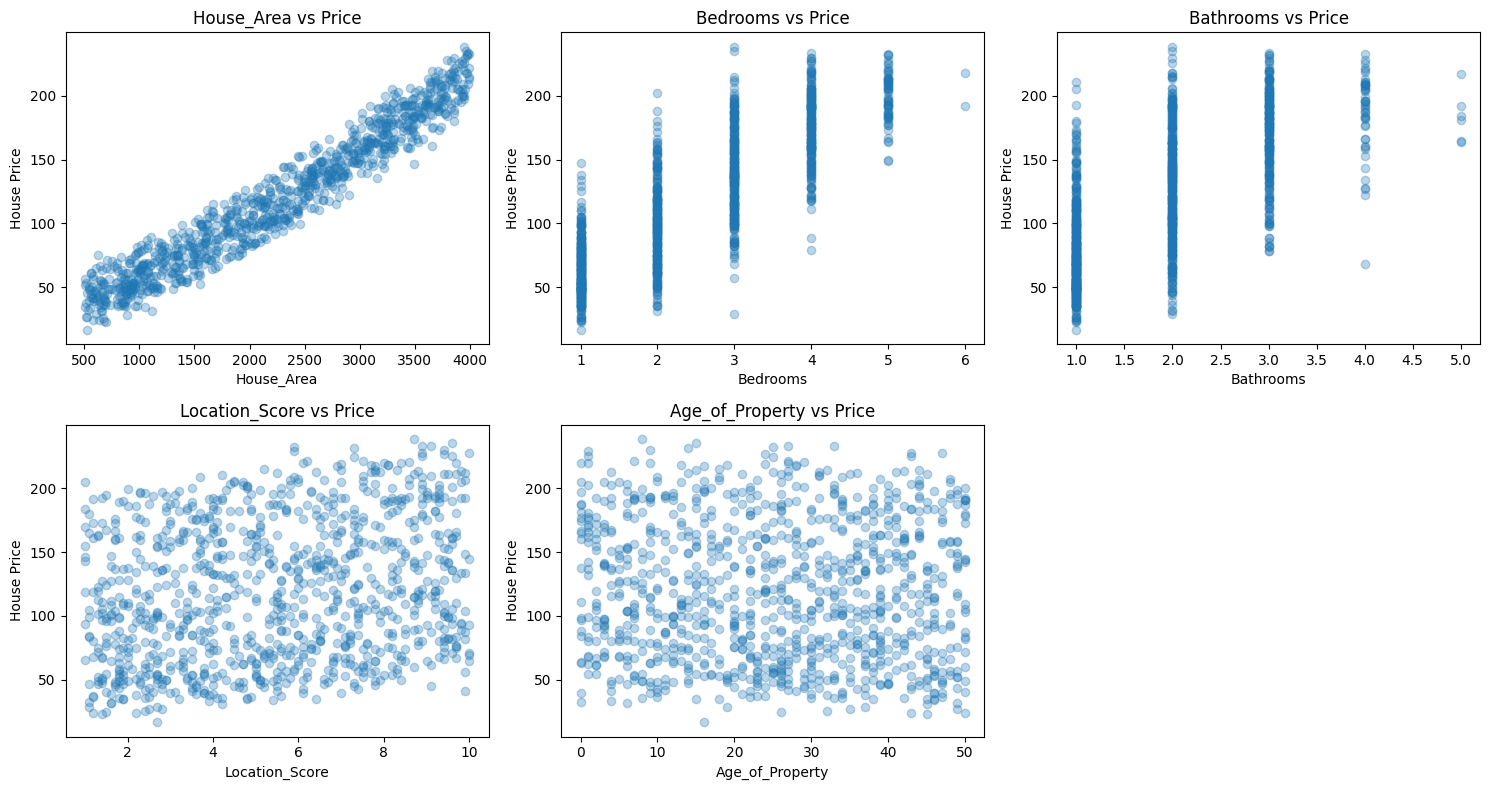

In [5]:
plt.figure(figsize=(15, 8))
for i, col in enumerate(X.columns):
    plt.subplot(2, 3, i + 1)
    plt.scatter(df[col], df["House_Price"], alpha=0.3)
    plt.xlabel(col)
    plt.ylabel("House Price")
    plt.title(col + " vs Price")
plt.tight_layout()
plt.show()

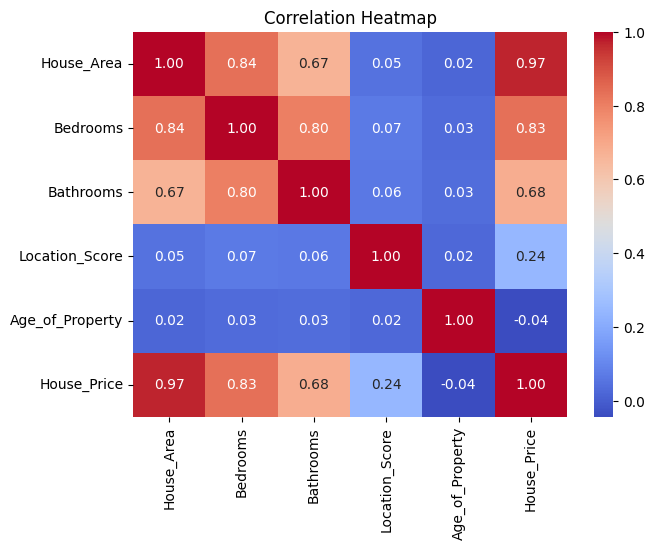

In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Interpretation:** House Area, Bedrooms, Bathrooms aur Location Score ka price ke saath **positive** relation hai (value badhi to price badhi). Age of Property ka **negative** relation hai (ghar purana to price kam). Area ka relation sabse strong hai. Heatmap me Area, Bedrooms aur Bathrooms aapas me bhi correlated dikhte hain.

### Task 9: Split the dataset into training and testing sets

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 800
Testing rows : 200


**Interpretation:** 80% data model ko train karne ke liye aur 20% data testing ke liye (jo model ne kabhi nahi dekha). `random_state=42` se har baar same split milta hai.

**Helper function:** niche ek chhota function hai jo baar baar metrics nikalne ke kaam aayega (MSE, MAE, RMSE, R², Adjusted R²).

In [8]:
def get_metrics(y_true, y_pred, n_features):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    return {"MSE": mse, "MAE": mae, "RMSE": rmse, "R2": r2, "Adj_R2": adj_r2}

# yaha saare models ke test results store honge (final report me kaam aayega)
results = {}

---
# 📈 Part C: Simple Linear Regression

### Task 10: Implement Simple Linear Regression (feature = House Area)

In [9]:
slr = LinearRegression()
slr.fit(X_train[["House_Area"]], y_train)

slr_pred_train = slr.predict(X_train[["House_Area"]])
slr_pred_test = slr.predict(X_test[["House_Area"]])

print("Slope     :", slr.coef_[0])
print("Intercept :", slr.intercept_)

Slope     : 0.05102580398071445
Intercept : 4.828290045179045


### Task 11: Plot the regression line and interpret slope and intercept

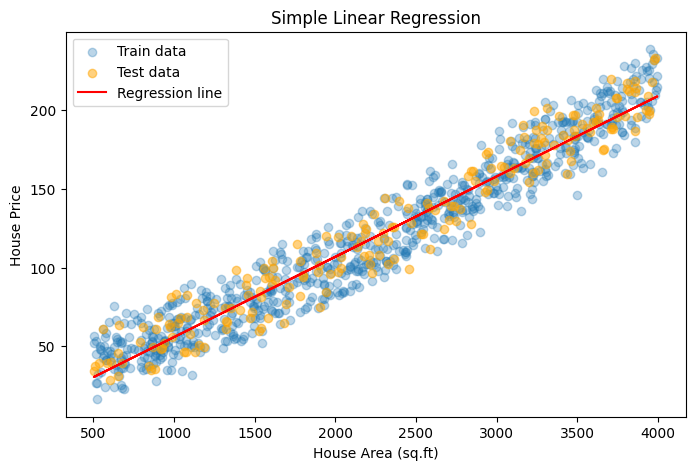

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train["House_Area"], y_train, alpha=0.3, label="Train data")
plt.scatter(X_test["House_Area"], y_test, alpha=0.5, color="orange", label="Test data")
plt.plot(X_train["House_Area"], slr_pred_train, color="red", label="Regression line")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [11]:
print("Slope =", round(slr.coef_[0], 4))
print("Har 1 sq.ft area badhne par price", round(slr.coef_[0], 4), "unit badhta hai")
print("Har 100 sq.ft par price", round(slr.coef_[0] * 100, 2), "unit badhta hai")
print()
print("Intercept =", round(slr.intercept_, 2), "(area 0 hone par base price, sirf mathematical value)")

Slope = 0.051
Har 1 sq.ft area badhne par price 0.051 unit badhta hai
Har 100 sq.ft par price 5.1 unit badhta hai

Intercept = 4.83 (area 0 hone par base price, sirf mathematical value)


**Interpretation:** Red line best-fit straight line hai. **Slope** batata hai area badhne par price kitna badhta hai. **Intercept** line ki starting value hai. Points line ke aas-paas scatter hain kyunki price sirf area par nahi, location, age aur rooms par bhi depend karta hai.

### Task 12: Validate Linear Regression Assumptions

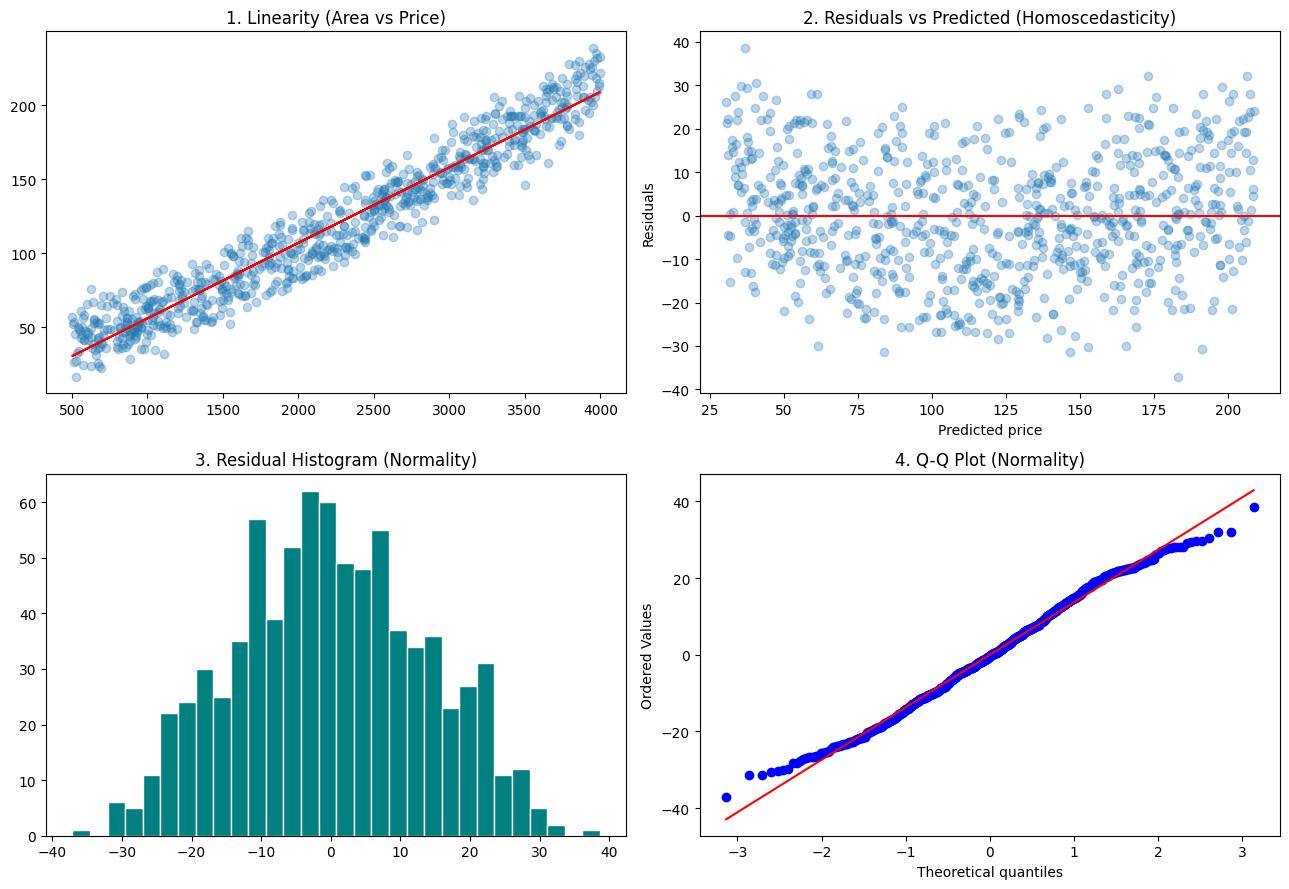

In [12]:
residuals = y_train - slr_pred_train      # actual - predicted

plt.figure(figsize=(13, 9))

# 1. Linearity
plt.subplot(2, 2, 1)
plt.scatter(X_train["House_Area"], y_train, alpha=0.3)
plt.plot(X_train["House_Area"], slr_pred_train, color="red")
plt.title("1. Linearity (Area vs Price)")

# 2. Homoscedasticity + Independence (residuals vs predicted)
plt.subplot(2, 2, 2)
plt.scatter(slr_pred_train, residuals, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Predicted price")
plt.ylabel("Residuals")
plt.title("2. Residuals vs Predicted (Homoscedasticity)")

# 3. Normality - histogram
plt.subplot(2, 2, 3)
plt.hist(residuals, bins=30, color="teal", edgecolor="white")
plt.title("3. Residual Histogram (Normality)")

# 4. Normality - QQ plot
plt.subplot(2, 2, 4)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("4. Q-Q Plot (Normality)")

plt.tight_layout()
plt.show()

**Observations:**
1. **Linearity:** Area aur Price ka relation almost straight line hai. ✔
2. **Independence / Homoscedasticity:** Residuals zero line ke aas-paas random scatter hain, koi funnel ya pattern nahi dikhta. ✔
3. **Normality:** Histogram bell-shape hai aur Q-Q plot ke points almost diagonal line par hain. ✔
4. **Multicollinearity:** Simple regression me ek hi feature hai, isliye ye check yaha apply nahi hota (Part E me multiple features ke saath dekhenge, correlation heatmap me Area/Bedrooms/Bathrooms thode correlated the).

Overall assumptions kaafi had tak satisfy ho rahi hain, isliye linear regression is data par use karna theek hai.

---
# 📊 Part D: Model Evaluation Metrics

### Task 13: Evaluate Simple Linear Regression (MSE, MAE, RMSE, R², Adjusted R²)

In [13]:
slr_train_m = get_metrics(y_train, slr_pred_train, 1)
slr_test_m = get_metrics(y_test, slr_pred_test, 1)
results["Simple Linear Regression"] = slr_test_m

pd.DataFrame({"Train": slr_train_m, "Test": slr_test_m}).round(3)

,Train,Test
MSE,187.621,160.393
MAE,11.182,10.301
RMSE,13.697,12.665
R2,0.935,0.947
Adj_R2,0.935,0.947


### Task 14: Interpret each metric

In [14]:
m = slr_test_m
print("MSE      =", round(m["MSE"], 2), " -> errors ke squares ka average (bade errors ko zyada punish karta hai)")
print("MAE      =", round(m["MAE"], 2), " -> prediction average itna galat hai")
print("RMSE     =", round(m["RMSE"], 2), " -> MSE ka square root, price ki same unit me typical error")
print("R2       =", round(m["R2"], 3), " -> model price ke variation ka", round(m["R2"] * 100, 1), "% explain karta hai")
print("Adj R2   =", round(m["Adj_R2"], 3), " -> R2 jo features ki count ke hisaab se adjust hota hai")

MSE      = 160.39  -> errors ke squares ka average (bade errors ko zyada punish karta hai)
MAE      = 10.3  -> prediction average itna galat hai
RMSE     = 12.66  -> MSE ka square root, price ki same unit me typical error
R2       = 0.947  -> model price ke variation ka 94.7 % explain karta hai
Adj R2   = 0.947  -> R2 jo features ki count ke hisaab se adjust hota hai


**Interpretation:**
- **MSE:** jitna kam utna accha. Squares hone se bade errors zyada count hote hain.
- **MAE:** average absolute error, samajhne me sabse easy.
- **RMSE:** typical error price ki apni unit me. Agar RMSE, MAE se kaafi bada ho to kuch predictions bahut galat hain.
- **R²:** 1 ke paas matlab accha fit, 0 matlab model average se behtar nahi.
- **Adjusted R²:** extra features add karne par sirf tab badhta hai jab feature sach me useful ho.
- Train aur test values ka comparison batata hai model generalize kar raha hai ya overfit.

---
# 📉 Part E: Multiple Linear Regression

### Task 15: Implement Multiple Linear Regression (all features)

In [15]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)

mlr_pred_train = mlr.predict(X_train)
mlr_pred_test = mlr.predict(X_test)

print("Intercept:", round(mlr.intercept_, 3))
pd.DataFrame({"Feature": X.columns, "Coefficient": mlr.coef_.round(4)})

Intercept: -11.624


,Feature,Coefficient
0,House_Area,0.0474
1,Bedrooms,1.7958
2,Bathrooms,2.2486
3,Location_Score,4.1119
4,Age_of_Property,-0.2544


**Interpretation:** Har coefficient batata hai ki baaki features same rakhne par us feature ke ek unit badhne se price kitna change hota hai. Area, Bedrooms, Bathrooms, Location ke coefficient **positive** hain, Age ka **negative** hai (purana ghar sasta).

### Task 16: Compare performance with Simple Linear Regression

In [16]:
mlr_train_m = get_metrics(y_train, mlr_pred_train, 5)
mlr_test_m = get_metrics(y_test, mlr_pred_test, 5)
results["Multiple Linear Regression"] = mlr_test_m

pd.DataFrame({"Simple LR (test)": slr_test_m, "Multiple LR (test)": mlr_test_m}).round(3)

,Simple LR (test),Multiple LR (test)
MSE,160.393,50.000
MAE,10.301,5.688
RMSE,12.665,7.071
R2,0.947,0.983
Adj_R2,0.947,0.983


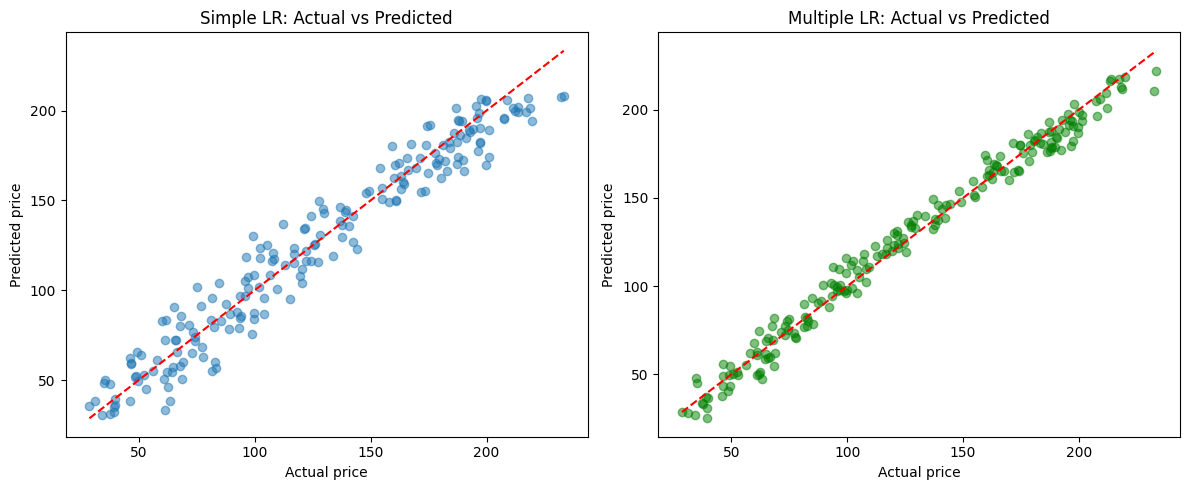

In [17]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, slr_pred_test, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Simple LR: Actual vs Predicted")

plt.subplot(1, 2, 2)
plt.scatter(y_test, mlr_pred_test, alpha=0.5, color="green")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Multiple LR: Actual vs Predicted")

plt.tight_layout()
plt.show()

### Task 17: Why does performance improve or degrade?

**Explanation:** Multiple Linear Regression ka performance **improve** hota hai (RMSE kam, R² aur Adjusted R² zyada) kyunki house price sirf area par nahi, **location, age, rooms** par bhi depend karta hai. Simple LR me ye information miss ho jati hai (high bias). MLR me zyada features hone se model price ko better explain karta hai. **Adjusted R² bhi badha**, matlab naye features sach me useful hain. Right side wale plot me points diagonal line ke paas hain, matlab predictions actual ke close hain.

Dhyan rahe: Area, Bedrooms, Bathrooms aapas me correlated hain (multicollinearity), isse individual coefficients thode unstable ho sakte hain, par overall prediction accha rehta hai.

---
# 🔁 Part F: Polynomial Regression

### Task 18: Implement Polynomial Regression (degree 2 and 3)
Polynomial regression me features ke powers (x², x³, ...) add karte hain taaki model **curve** seekh sake. Pehle features ko scale kar rahe hain taaki bade numbers (area) problem na karein.

In [18]:
# Scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Degree 2
poly2 = PolynomialFeatures(degree=2)
X_train_p2 = poly2.fit_transform(X_train_s)
X_test_p2 = poly2.transform(X_test_s)
model_p2 = LinearRegression().fit(X_train_p2, y_train)

# Degree 3
poly3 = PolynomialFeatures(degree=3)
X_train_p3 = poly3.fit_transform(X_train_s)
X_test_p3 = poly3.transform(X_test_s)
model_p3 = LinearRegression().fit(X_train_p3, y_train)

p2_train_pred = model_p2.predict(X_train_p2)
p2_test_pred = model_p2.predict(X_test_p2)
p3_train_pred = model_p3.predict(X_train_p3)
p3_test_pred = model_p3.predict(X_test_p3)

print("Degree 2 features:", X_train_p2.shape[1])
print("Degree 3 features:", X_train_p3.shape[1])

Degree 2 features: 21
Degree 3 features: 56


### Task 19: Compare Linear vs Polynomial (visually and numerically)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


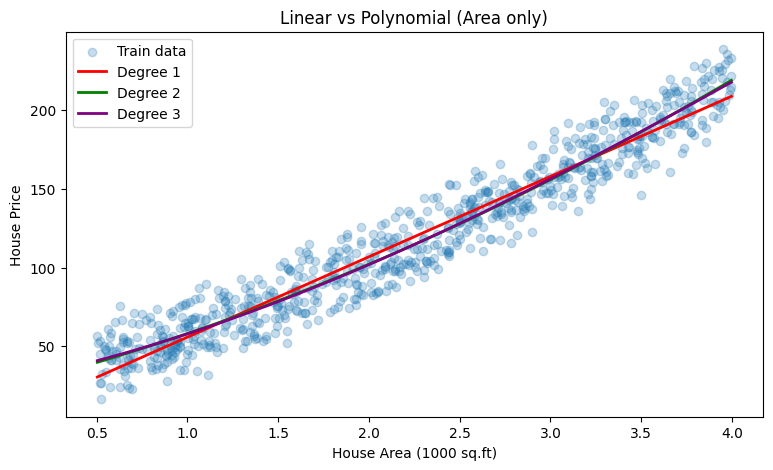

In [19]:
# Visual comparison: sirf House Area use karke (taaki curve dikh sake)
area_train = X_train[["House_Area"]] / 1000        # 1000 se divide: numbers chhote
grid = np.linspace(X["House_Area"].min(), X["House_Area"].max(), 200).reshape(-1, 1) / 1000

plt.figure(figsize=(9, 5))
plt.scatter(area_train, y_train, alpha=0.25, label="Train data")

for degree, color in [(1, "red"), (2, "green"), (3, "purple")]:
    pf = PolynomialFeatures(degree=degree)
    m = LinearRegression().fit(pf.fit_transform(area_train), y_train)
    plt.plot(grid, m.predict(pf.transform(grid)), color=color, linewidth=2, label="Degree " + str(degree))

plt.xlabel("House Area (1000 sq.ft)")
plt.ylabel("House Price")
plt.title("Linear vs Polynomial (Area only)")
plt.legend()
plt.show()

In [20]:
p2_train_m = get_metrics(y_train, p2_train_pred, X_train_p2.shape[1] - 1)
p2_test_m = get_metrics(y_test, p2_test_pred, X_train_p2.shape[1] - 1)
p3_train_m = get_metrics(y_train, p3_train_pred, X_train_p3.shape[1] - 1)
p3_test_m = get_metrics(y_test, p3_test_pred, X_train_p3.shape[1] - 1)

results["Polynomial (degree 2)"] = p2_test_m
results["Polynomial (degree 3)"] = p3_test_m

pd.DataFrame({"Simple LR": slr_test_m, "Multiple LR": mlr_test_m,
              "Poly deg 2": p2_test_m, "Poly deg 3": p3_test_m}).round(3)

,Simple LR,Multiple LR,Poly deg 2,Poly deg 3
MSE,160.393,50.000,36.347,38.231
MAE,10.301,5.688,4.916,5.003
RMSE,12.665,7.071,6.029,6.183
R2,0.947,0.983,0.988,0.987
Adj_R2,0.947,0.983,0.987,0.983


**Interpretation:** Graph me degree 1 (red) seedhi line hai, degree 2 aur 3 halki si curve banate hain jo data ke trend ko thoda better follow karti hai. Table me polynomial models ka RMSE linear se kam aur R² zyada hai, matlab data me halka sa non-linear pattern hai. Degree 3 ka fayda degree 2 se zyada nahi hai.

### Task 20: Identify signs of Overfitting or Underfitting

In [21]:
# Degree 1 se 5 tak try karte hain aur train vs test error dekhte hain
degrees = [1, 2, 3, 4, 5]
train_rmse_list = []
test_rmse_list = []

for d in degrees:
    pf = PolynomialFeatures(degree=d)
    Xtr = pf.fit_transform(X_train_s)
    Xte = pf.transform(X_test_s)
    m = LinearRegression().fit(Xtr, y_train)
    train_rmse_list.append(np.sqrt(mean_squared_error(y_train, m.predict(Xtr))))
    test_rmse_list.append(np.sqrt(mean_squared_error(y_test, m.predict(Xte))))

pd.DataFrame({"Degree": degrees, "Train RMSE": np.round(train_rmse_list, 2),
              "Test RMSE": np.round(test_rmse_list, 2)})

,Degree,Train RMSE,Test RMSE
0,1,7.09,7.07
1,2,5.98,6.03
2,3,5.86,6.18
3,4,5.57,6.71
4,5,5.16,15.95


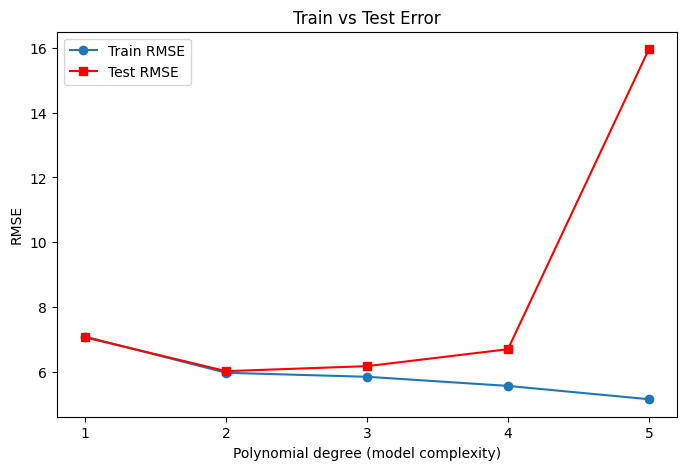

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rmse_list, "o-", label="Train RMSE")
plt.plot(degrees, test_rmse_list, "s-", color="red", label="Test RMSE")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("RMSE")
plt.title("Train vs Test Error")
plt.xticks(degrees)
plt.legend()
plt.show()

**Signs:**
- **Underfitting:** degree 1 (linear) me train aur test dono error zyada hai, model data ko poora capture nahi kar pa raha.
- **Good fit:** degree 2 me test error sabse kam hai.
- **Overfitting:** degree badhne par **train error kam hota rehta hai** lekin **test error badhne lagta hai** (degree 4, 5). Degree 5 me train aur test ke beech bada gap hai, matlab model training data ko ratt raha hai (memorize).

---
# ⚙️ Part G: Gradient Descent Optimization

### Task 21: Explain Gradient Descent conceptually
**Gradient Descent** ek optimization method hai jisse model ke best weights (w) milte hain, jahan **cost (error) minimum** ho. Linear regression me cost = MSE.

Steps:
1. Weights random/zero se start karo.
2. Cost ka **gradient** (slope) nikalo.
3. Weights ko gradient ki **ulti direction** me thoda sa update karo: `w = w - learning_rate × gradient`
4. Ye baar baar karo jab tak cost minimum na ho jaye.

Socho pahaad se neeche utar rahe ho: gradient batata hai kaunsi direction me dhalaan hai, **learning rate** step ka size hai (bahut chhota = slow, bahut bada = overshoot).

| Type | Ek update me kitna data | Nature |
|---|---|---|
| **Batch GD** | poora training data | smooth, stable, slow |
| **Stochastic GD (SGD)** | sirf 1 sample | fast updates, noisy |
| **Mini-Batch GD** | chhota batch (e.g. 32) | balance of both |

**Data preparation:** GD ke liye features scale karna zaroori hai (Area hazaaron me, Age tens me hota hai). Isliye mean/std se standardize kar rahe hain (sirf training data ke mean/std se).

In [23]:
# Features aur target ko standardize karna
x_mean = X_train.mean()
x_std = X_train.std()
y_mean = y_train.mean()
y_std = y_train.std()

Xtr = ((X_train - x_mean) / x_std).values
Xte = ((X_test - x_mean) / x_std).values
ytr = ((y_train - y_mean) / y_std).values

# bias (intercept) ke liye 1 wala column add karna
Xtr = np.c_[np.ones(len(Xtr)), Xtr]
Xte = np.c_[np.ones(len(Xte)), Xte]

def compute_cost(X, y, w):
    errors = X @ w - y
    return np.mean(errors ** 2) / 2

print("Xtr shape:", Xtr.shape)

Xtr shape: (800, 6)


### Task 22: Implement Batch Gradient Descent from scratch

In [24]:
w = np.zeros(Xtr.shape[1])
learning_rate = 0.1
epochs = 200
cost_batch = []

start = time.time()
for epoch in range(epochs):
    predictions = Xtr @ w
    gradient = Xtr.T @ (predictions - ytr) / len(ytr)      # poore data se gradient
    w = w - learning_rate * gradient
    cost_batch.append(compute_cost(Xtr, ytr, w))
time_batch = time.time() - start

w_batch = w
print("Batch GD final cost:", round(cost_batch[-1], 5))
print("Time taken:", round(time_batch, 4), "sec")

Batch GD final cost: 0.00883
Time taken: 0.0033 sec


### Task 23: Implement Stochastic Gradient Descent (SGD)

In [25]:
w = np.zeros(Xtr.shape[1])
learning_rate = 0.01
epochs = 30
cost_sgd = []

start = time.time()
for epoch in range(epochs):
    for i in np.random.permutation(len(ytr)):               # random order me ek-ek sample
        xi = Xtr[i]
        error = xi @ w - ytr[i]
        w = w - learning_rate * error * xi                  # sirf 1 sample se update
    cost_sgd.append(compute_cost(Xtr, ytr, w))
time_sgd = time.time() - start

w_sgd = w
print("SGD final cost:", round(cost_sgd[-1], 5))
print("Time taken:", round(time_sgd, 4), "sec")

SGD final cost: 0.00889
Time taken: 0.0687 sec


### Task 24: Implement Mini-Batch Gradient Descent

In [26]:
w = np.zeros(Xtr.shape[1])
learning_rate = 0.05
epochs = 100
batch_size = 32
cost_mini = []

start = time.time()
for epoch in range(epochs):
    idx = np.random.permutation(len(ytr))                   # data shuffle
    for s in range(0, len(ytr), batch_size):
        batch = idx[s:s + batch_size]
        Xb = Xtr[batch]
        yb = ytr[batch]
        gradient = Xb.T @ (Xb @ w - yb) / len(yb)           # chhote batch se gradient
        w = w - learning_rate * gradient
    cost_mini.append(compute_cost(Xtr, ytr, w))
time_mini = time.time() - start

w_mini = w
print("Mini-Batch GD final cost:", round(cost_mini[-1], 5))
print("Time taken:", round(time_mini, 4), "sec")

Mini-Batch GD final cost: 0.00876
Time taken: 0.0237 sec


### Task 25: Compare convergence behavior and training time of all three methods

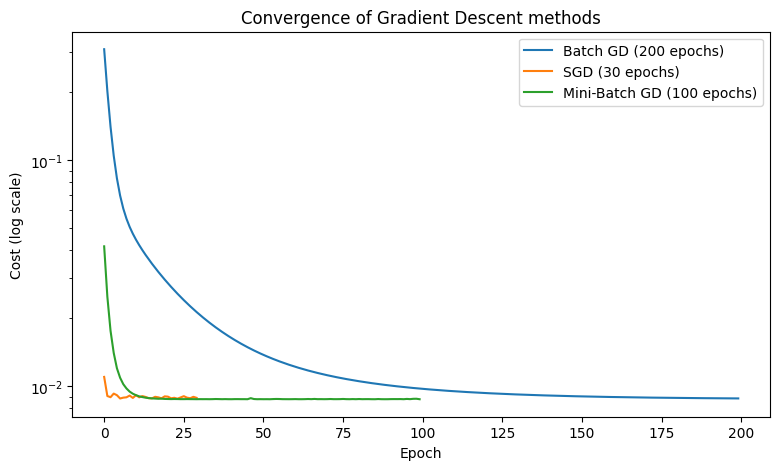

In [27]:
plt.figure(figsize=(9, 5))
plt.plot(cost_batch, label="Batch GD (200 epochs)")
plt.plot(cost_sgd, label="SGD (30 epochs)")
plt.plot(cost_mini, label="Mini-Batch GD (100 epochs)")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Cost (log scale)")
plt.title("Convergence of Gradient Descent methods")
plt.legend()
plt.show()

In [28]:
# Predictions ko wapas original price scale me convert karke test accuracy nikalte hain
def gd_predict(w):
    return (Xte @ w) * y_std + y_mean

rows = []
for name, w_, t_, c_ in [("Batch GD", w_batch, time_batch, cost_batch),
                         ("SGD", w_sgd, time_sgd, cost_sgd),
                         ("Mini-Batch GD", w_mini, time_mini, cost_mini)]:
    m = get_metrics(y_test, gd_predict(w_), 5)
    results[name] = m
    rows.append([name, round(c_[-1], 5), round(t_ * 1000, 1), round(m["RMSE"], 3), round(m["R2"], 4)])

gd_table = pd.DataFrame(rows, columns=["Method", "Final cost", "Time (ms)", "Test RMSE", "Test R2"])
gd_table.loc[len(gd_table)] = ["Normal LinearRegression (sklearn)", None, None,
                               round(mlr_test_m["RMSE"], 3), round(mlr_test_m["R2"], 4)]
gd_table

,Method,Final cost,Time (ms),Test RMSE,Test R2
0,Batch GD,0.00883,3.3,7.177,0.9830
1,SGD,0.00889,68.7,7.194,0.9829
2,Mini-Batch GD,0.00876,23.7,7.074,0.9834
3,Normal LinearRegression (sklearn),None,None,7.071,0.9835


**Comparison:**
- **Batch GD:** curve smooth hai, har epoch me ek hi update hota hai, isliye converge hone me zyada epochs lagte hain. Chhote data par time kam hai, par bade data me slow hoga.
- **SGD:** bahut kam epochs me achha cost mil jaata hai kyunki ek epoch me hazaaron updates hote hain. Par path **noisy** hota hai aur Python loop me time zyada lagta hai.
- **Mini-Batch GD:** dono ka balance. Batch se kam epochs me converge hota hai aur SGD se zyada stable hai. Deep learning me isi ka use hota hai.
- Teeno methods ka **Test RMSE normal LinearRegression ke almost barabar** hai, matlab hamara from-scratch implementation sahi kaam kar raha hai.

---
# 📐 Part H: Bias–Variance & Model Diagnostics

### Task 26: Analyze bias and variance across the models
Simple tareeka (student level):
- **Train error zyada** = model data ko achhe se nahi seekh paya = **High Bias**
- **Train aur test error me bada gap** (test >> train) = **High Variance**

In [29]:
# Polynomial degree 5 bhi liya hai (contrast ke liye, complex model)
pf5 = PolynomialFeatures(degree=5)
Xtr5 = pf5.fit_transform(X_train_s)
Xte5 = pf5.transform(X_test_s)
model_p5 = LinearRegression().fit(Xtr5, y_train)

models = {
    "Simple Linear Regression": (slr_pred_train, slr_pred_test),
    "Multiple Linear Regression": (mlr_pred_train, mlr_pred_test),
    "Polynomial (degree 2)": (p2_train_pred, p2_test_pred),
    "Polynomial (degree 3)": (p3_train_pred, p3_test_pred),
    "Polynomial (degree 5)": (model_p5.predict(Xtr5), model_p5.predict(Xte5)),
}

rows = []
for name, (tr_pred, te_pred) in models.items():
    tr_rmse = np.sqrt(mean_squared_error(y_train, tr_pred))
    te_rmse = np.sqrt(mean_squared_error(y_test, te_pred))
    rows.append([name, round(tr_rmse, 2), round(te_rmse, 2), round(te_rmse - tr_rmse, 2)])

bv_table = pd.DataFrame(rows, columns=["Model", "Train RMSE (bias)", "Test RMSE", "Gap (variance)"])
bv_table

,Model,Train RMSE (bias),Test RMSE,Gap (variance)
0,Simple Linear Regression,13.70,12.66,-1.03
1,Multiple Linear Regression,7.09,7.07,-0.02
2,Polynomial (degree 2),5.98,6.03,0.05
3,Polynomial (degree 3),5.86,6.18,0.33
4,Polynomial (degree 5),5.16,15.95,10.79


**Analysis:**
- **Simple Linear Regression:** train error sabse zyada, gap chhota = **High Bias, Low Variance** (underfit).
- **Multiple Linear Regression:** train error kaafi kam, gap chhota = bias kam, variance bhi kam.
- **Polynomial deg 2 / 3:** bias aur kam hota hai, gap thoda sa badhta hai.
- **Polynomial deg 5:** train error sabse kam but test error bahut zyada, bada gap = **Low Bias, High Variance** (overfit).

### Task 27: Explain how model complexity affects prediction error

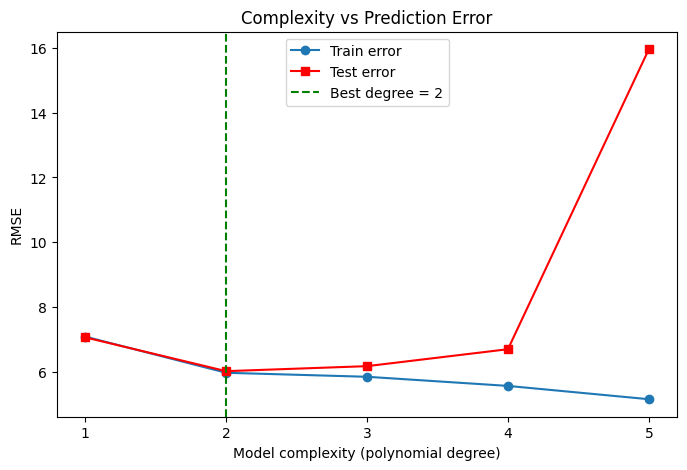

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rmse_list, "o-", label="Train error")
plt.plot(degrees, test_rmse_list, "s-", color="red", label="Test error")
best_degree = degrees[int(np.argmin(test_rmse_list))]
plt.axvline(best_degree, color="green", linestyle="--", label="Best degree = " + str(best_degree))
plt.xlabel("Model complexity (polynomial degree)")
plt.ylabel("RMSE")
plt.title("Complexity vs Prediction Error")
plt.xticks(degrees)
plt.legend()
plt.show()

**Explanation:** Jaise jaise model **complex** hota hai (degree badhta hai):
- **Bias kam hota hai** (model zyada patterns pakad leta hai) aur **train error hamesha kam hota jaata hai**.
- **Variance badhta hai** (model noise bhi seekhne lagta hai), isliye **test error pehle kam hota hai fir badhne lagta hai** (U-shape).

Best model wo hai jahan test error sabse kam ho (green line), na bahut simple, na bahut complex.

### Task 28: Which model best balances bias and variance?

In [31]:
best_row = bv_table.loc[bv_table["Test RMSE"].idxmin()]
print("Lowest test error wala model:", best_row["Model"])
print("Test RMSE:", best_row["Test RMSE"], "| Gap:", best_row["Gap (variance)"])

Lowest test error wala model: Polynomial (degree 2)
Test RMSE: 6.03 | Gap: 0.05


**Conclusion:** Jis model ka **test RMSE sabse kam** hai aur train-test gap bhi chhota hai wahi bias aur variance ko best balance karta hai. Humare data me ye **Polynomial Regression (degree 2)** hai. **Multiple Linear Regression** bhi bahut close hai aur simple + easy to explain hai. Simple LR bahut biased hai aur degree 5 bahut zyada variance wala hai.

---
# 🧾 Part I: Final Analysis & Reporting

### Task 29: Summarize findings in a short report

In [32]:
final_table = pd.DataFrame(results).T[["RMSE", "MAE", "R2", "Adj_R2"]].round(3)
final_table = final_table.sort_values("RMSE")
final_table

,RMSE,MAE,R2,Adj_R2
Polynomial (degree 2),6.029,4.916,0.988,0.987
Polynomial (degree 3),6.183,5.003,0.987,0.983
Multiple Linear Regression,7.071,5.688,0.983,0.983
Mini-Batch GD,7.074,5.688,0.983,0.983
Batch GD,7.177,5.821,0.983,0.983
SGD,7.194,5.734,0.983,0.982
Simple Linear Regression,12.665,10.301,0.947,0.947


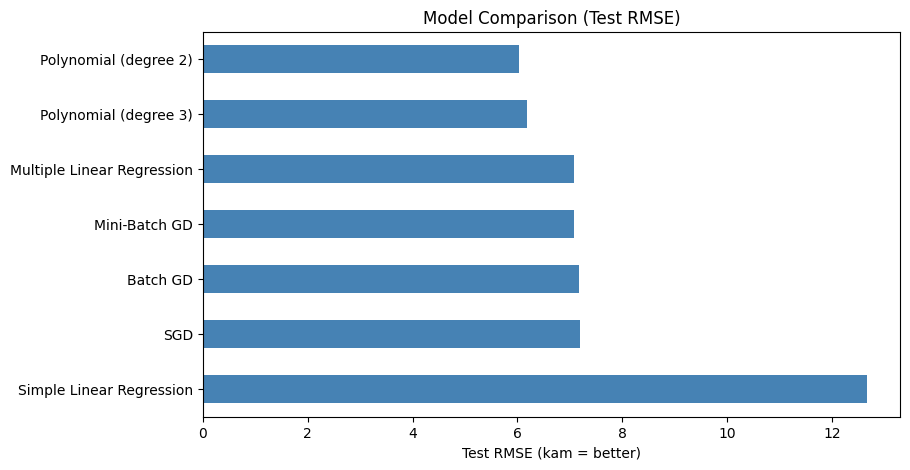

In [33]:
final_table["RMSE"].plot(kind="barh", figsize=(9, 5), color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("Test RMSE (kam = better)")
plt.title("Model Comparison (Test RMSE)")
plt.show()

In [34]:
best_model = final_table.index[0]
print("Best performing model:", best_model)
print("Test RMSE:", final_table.iloc[0]["RMSE"], "| Test R2:", final_table.iloc[0]["R2"])
print()
print("Business interpretation (Multiple LR coefficients):")
coef = pd.Series(mlr.coef_, index=X.columns)
print("  +100 sq.ft area      ->", round(coef["House_Area"] * 100, 2), "price units")
print("  +1 location score    ->", round(coef["Location_Score"], 2))
print("  +1 bedroom           ->", round(coef["Bedrooms"], 2))
print("  +1 bathroom          ->", round(coef["Bathrooms"], 2))
print("  +1 year property age ->", round(coef["Age_of_Property"], 2))

Best performing model: Polynomial (degree 2)
Test RMSE: 6.029 | Test R2: 0.988

Business interpretation (Multiple LR coefficients):
  +100 sq.ft area      -> 4.74 price units
  +1 location score    -> 4.11
  +1 bedroom           -> 1.8
  +1 bathroom          -> 2.25
  +1 year property age -> -0.25


### 📝 Short Report

**1. Best-performing model and why:**
Table ke hisaab se **Polynomial Regression (degree 2)** ka test error sabse kam hai. Isne saari features use ki aur halka sa curve bhi capture kiya, isliye bias kam hai aur complexity kam hone se variance bhi control me hai. Multiple Linear Regression bahut close second hai aur zyada simple/interpretable hai. Simple LR sabse weak hai kyunki sirf area use karta hai.

**2. Impact of gradient descent optimization:**
Batch, SGD aur Mini-Batch teeno ne almost wahi result diya jo normal LinearRegression deta hai, matlab GD weights sahi seekhta hai. SGD kam epochs me converge hota hai par noisy hai, Batch smooth hai par zyada epochs leta hai, Mini-Batch best balance hai. Feature scaling aur sahi learning rate zaroori the.

**3. Evidence of overfitting / underfitting:**
- *Underfitting:* Simple Linear Regression me error zyada hai (ek feature kaafi nahi).
- *Overfitting:* Polynomial degree 5 me train error bahut kam par test error bahut zyada (bada gap). Degree 2 ke baad test error badhne lagta hai.

**4. Practical business interpretation:**
Ghar ki **price ko sabse zyada area aur location score badhate hain**, jabki **age badhne par price ghatta hai**. Model ka typical error MAE jitna hai, isliye ye tez price estimate / screening ke liye useful hai, par bade deals me expert valuation bhi zaroori hai.

### Task 30: Submit (Source code, Evaluation results, Graphs, Final conclusion)

- ✅ **Source code:** ye notebook (`.ipynb`)
- ✅ **Model evaluation results:** Task 13, 16, 19, 25, 26 aur 29 ke tables
- ✅ **Graphs and plots:** notebook me sab plots + `images/` folder ke screenshots
- ✅ **Final conclusion:** niche

### 🏁 Final Conclusion
1. Simple Linear Regression **underfit** karta hai kyunki ek feature se price predict nahi ho sakta.
2. Multiple Linear Regression error bahut kam kar deta hai, kyunki location, age aur rooms bhi price ko affect karte hain.
3. Low-degree **Polynomial Regression (degree 2)** sabse accha balance deta hai, par bahut high degree (5) **overfit** ho jata hai.
4. **Gradient Descent** (Batch, SGD, Mini-Batch) normal linear regression jaisa hi result deta hai, Mini-Batch practical choice hai.
5. Sabse accha model sabse complex model nahi hota, balki wo hota hai jisme **bias aur variance ka balance** ho.